In [1]:
import ast
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import wfdb

from pathlib import Path
from torch.utils.data import Dataset

In [2]:
PROJECT_ROOT = Path("..")

PTBXL_DIR = PROJECT_ROOT / "data" / "raw" / "ptb-xl"

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

REPORTS_DIR = PROJECT_ROOT / "reports"

REPORTS_DIR.mkdir(parents=True, exist_ok=True)

print(PTBXL_DIR)

../data/raw/ptb-xl


In [3]:
df = pd.read_csv(PTBXL_DIR / "ptbxl_database.csv")

scp = pd.read_csv(PTBXL_DIR / "scp_statements.csv", index_col=0)

df["scp_codes_dict"] = df["scp_codes"].apply(ast.literal_eval)

print("Metadata:", df.shape)

print("SCP:", scp.shape)

Metadata: (21799, 29)
SCP: (71, 12)


In [4]:
diagnostic_mapping = scp[scp["diagnostic"] == 1]["diagnostic_class"].dropna().to_dict()

print("Diagnostic codes:", len(diagnostic_mapping))

Diagnostic codes: 44


In [5]:
def get_diagnostic_classes(codes, mapping):
    classes = set()

    for code in codes:

        diagnostic_class = mapping.get(code)

        if pd.notna(diagnostic_class):
            classes.add(diagnostic_class)

    return sorted(classes)

In [6]:
df["diagnostic_classes"] = df["scp_codes_dict"].apply(
    lambda codes: get_diagnostic_classes(codes, diagnostic_mapping)
)

In [7]:
TARGET_CLASSES = ["NORM", "MI", "STTC", "CD", "HYP"]

print(TARGET_CLASSES)

['NORM', 'MI', 'STTC', 'CD', 'HYP']


In [8]:
for class_name in TARGET_CLASSES:

    df[f"label_{class_name}"] = df["diagnostic_classes"].apply(
        lambda classes: int(class_name in classes)
    )

In [9]:
df[
    [
        "ecg_id",
        "diagnostic_classes",
        "label_NORM",
        "label_MI",
        "label_STTC",
        "label_CD",
        "label_HYP",
    ]
].head(20)

,ecg_id,diagnostic_classes,label_NORM,label_MI,label_STTC,label_CD,label_HYP
0,1,[NORM],1,0,0,0,0
1,2,[NORM],1,0,0,0,0
2,3,[NORM],1,0,0,0,0
3,4,[NORM],1,0,0,0,0
4,5,[NORM],1,0,0,0,0
5,6,[NORM],1,0,0,0,0
6,7,[NORM],1,0,0,0,0
7,8,[MI],0,1,0,0,0
8,9,[NORM],1,0,0,0,0
9,10,[NORM],1,0,0,0,0


In [10]:
label_columns = [f"label_{cls}" for cls in TARGET_CLASSES]

df["num_labels"] = df[label_columns].sum(axis=1)

print(df["num_labels"].value_counts().sort_index())

num_labels
0      411
1    16244
2     4068
3      919
4      157
Name: count, dtype: int64


In [11]:
print(
    "ECGs with multiple diagnostic classes:",
    (df["num_labels"] > 1).sum(),
)

ECGs with multiple diagnostic classes: 5144


In [12]:
df_model = df[df["num_labels"] > 0].copy()

In [13]:
print("Original recordings:", len(df))

print("Usable labeled recordings:", len(df_model))

print("Removed:", len(df) - len(df_model))

Original recordings: 21799
Usable labeled recordings: 21388
Removed: 411


In [14]:
train_df = df_model[df_model["strat_fold"].between(1, 8)].copy()

val_df = df_model[df_model["strat_fold"] == 9].copy()

test_df = df_model[df_model["strat_fold"] == 10].copy()

In [15]:
print("Train:", train_df.shape)

print("Validation:", val_df.shape)

print("Test:", test_df.shape)

Train: (17084, 36)
Validation: (2146, 36)
Test: (2158, 36)


In [16]:
print("TRAIN")
print(train_df[label_columns].sum())

print("\nVALIDATION")
print(val_df[label_columns].sum())

print("\nTEST")
print(test_df[label_columns].sum())

TRAIN
label_NORM    7596
label_MI      4379
label_STTC    4186
label_CD      3907
label_HYP     2119
dtype: int64

VALIDATION
label_NORM    955
label_MI      540
label_STTC    528
label_CD      495
label_HYP     268
dtype: int64

TEST
label_NORM    963
label_MI      550
label_STTC    521
label_CD      496
label_HYP     262
dtype: int64


In [17]:
record_path = PTBXL_DIR / train_df["filename_lr"].iloc[0]

record = wfdb.rdrecord(str(record_path))

print("Sampling frequency:", record.fs)

print("Signal shape:", record.p_signal.shape)

print("Leads:", record.sig_name)

Sampling frequency: 100
Signal shape: (1000, 12)
Leads: ['I', 'II', 'III', 'AVR', 'AVL', 'AVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']


In [18]:
signal = record.p_signal

print("Shape:", signal.shape)

print("Min:", signal.min())

print("Max:", signal.max())

print("Mean:", signal.mean())

print("Std:", signal.std())

Shape: (1000, 12)
Min: -1.377
Max: 0.706
Mean: 0.00010474999999999864
Std: 0.1076345473230482


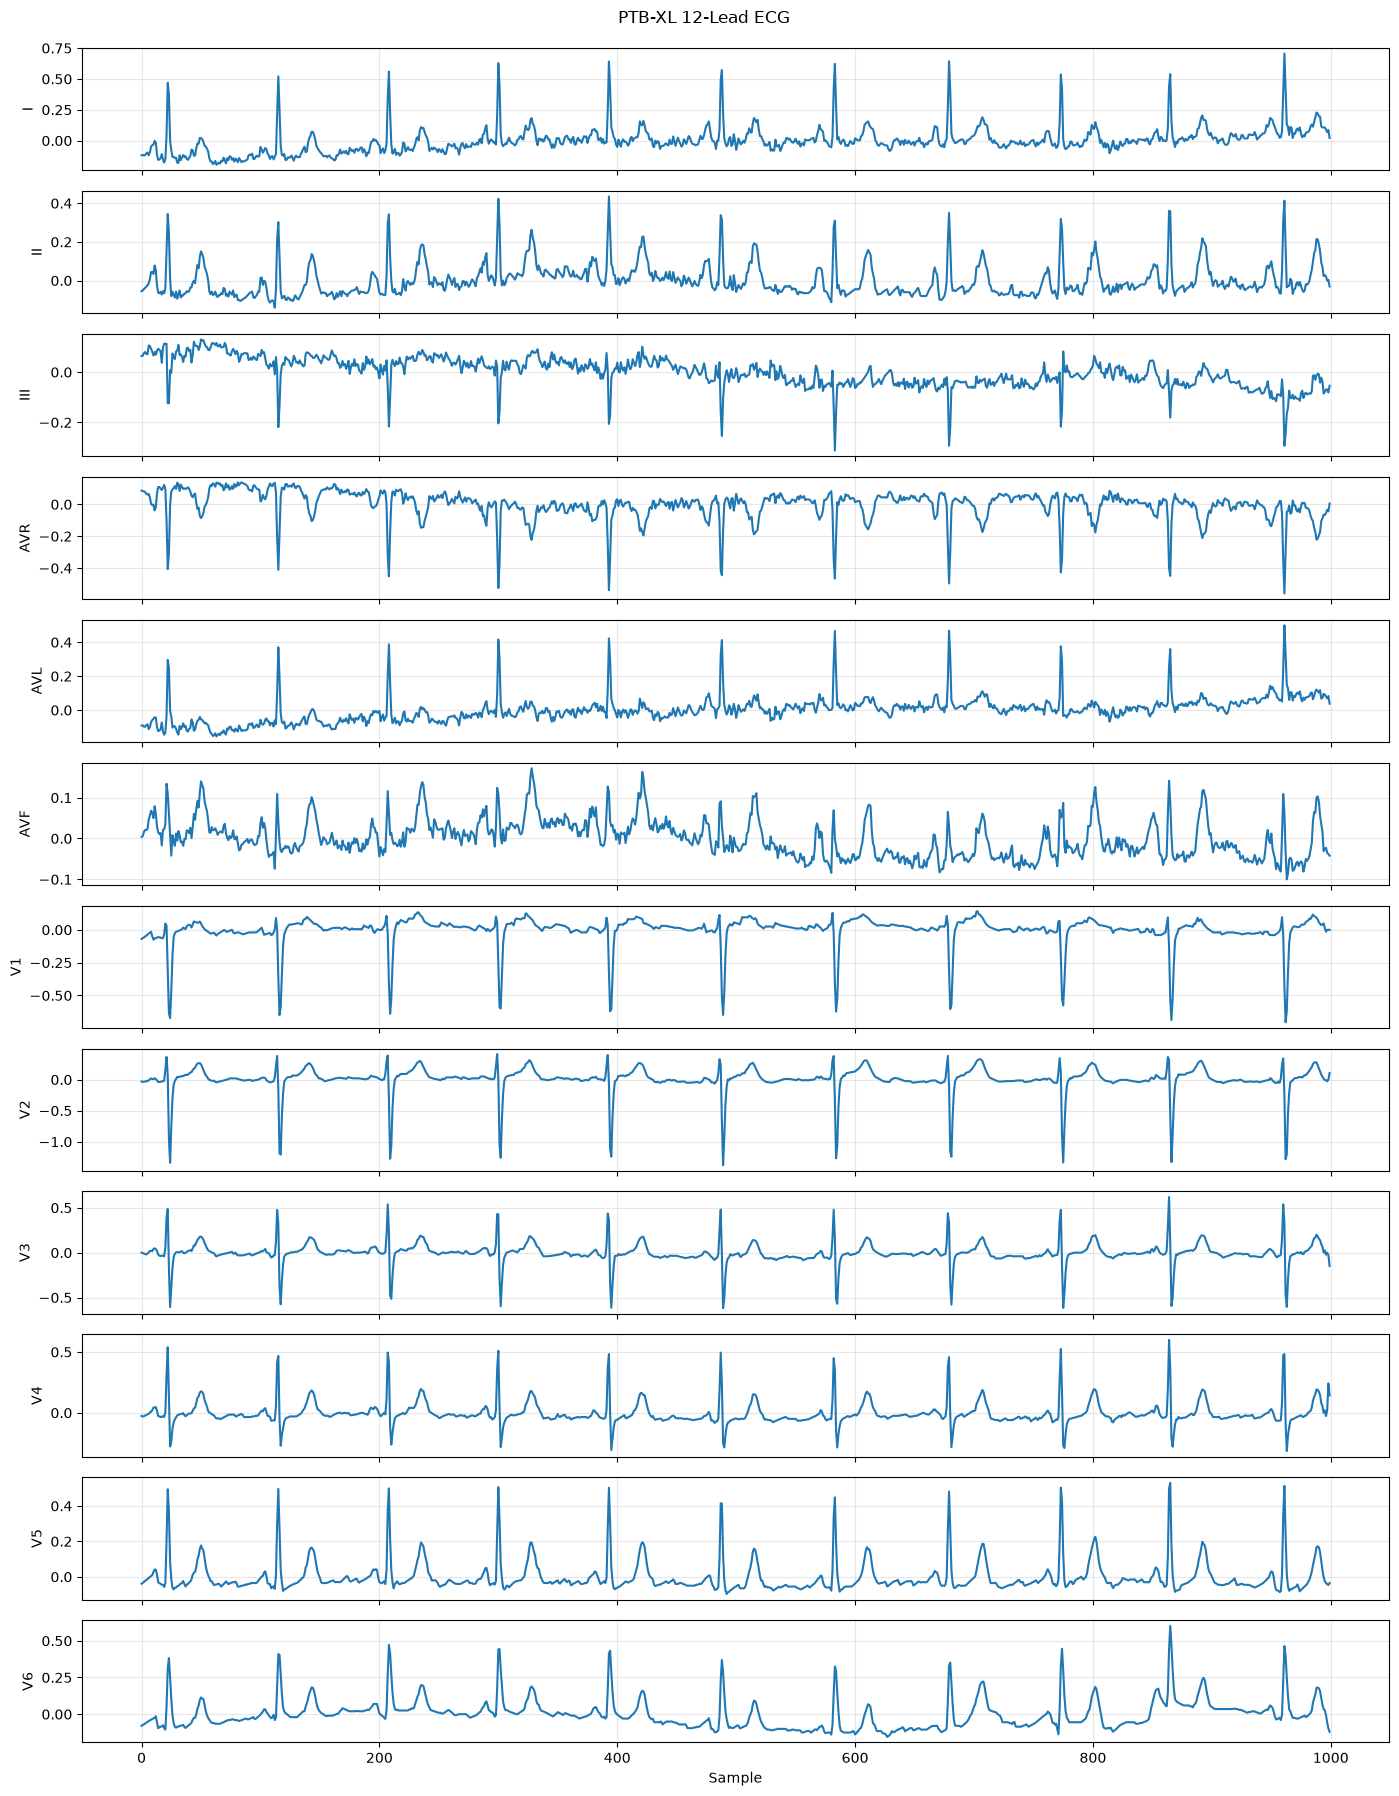

In [19]:
fig, axes = plt.subplots(12, 1, figsize=(14, 18), sharex=True)

for i, ax in enumerate(axes):

    ax.plot(signal[:, i])

    ax.set_ylabel(record.sig_name[i])

    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Sample")

fig.suptitle("PTB-XL 12-Lead ECG", y=0.995)

plt.tight_layout()
plt.show()

In [20]:
sample_lengths = []

for path in train_df["filename_lr"].head(100):

    record = wfdb.rdrecord(str(PTBXL_DIR / path))

    sample_lengths.append(record.p_signal.shape[0])

pd.Series(sample_lengths).value_counts().sort_index()

1000    100
Name: count, dtype: int64

In [21]:
sampling_rates = []

for path in train_df["filename_lr"].head(100):

    record = wfdb.rdrecord(str(PTBXL_DIR / path))

    sampling_rates.append(record.fs)

pd.Series(sampling_rates).value_counts()

100    100
Name: count, dtype: int64

In [22]:
def normalize_ecg(signal):
    mean = signal.mean(
        axis=0,
        keepdims=True,
    )

    std = signal.std(
        axis=0,
        keepdims=True,
    )

    std = np.where(
        std < 1e-8,
        1.0,
        std,
    )

    return (signal - mean) / std

In [23]:
normalized_signal = normalize_ecg(signal)

print("Original mean:", signal.mean(axis=0))

print("Normalized mean:", normalized_signal.mean(axis=0))

print("Normalized std:", normalized_signal.std(axis=0))

Original mean: [ 1.508e-03  7.230e-04 -7.780e-04 -1.113e-03  1.211e-03  7.000e-06
 -1.709e-03  6.999e-03 -1.777e-03 -4.089e-03 -5.570e-04  8.320e-04]
Normalized mean: [-1.45661261e-16  8.97615315e-17 -3.01614289e-15  2.97192826e-16
 -2.76556555e-16 -1.88959959e-16 -3.81014664e-17 -1.23789867e-17
 -4.64073224e-17 -1.28341782e-16 -2.80886425e-17  3.53939100e-16]
Normalized std: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


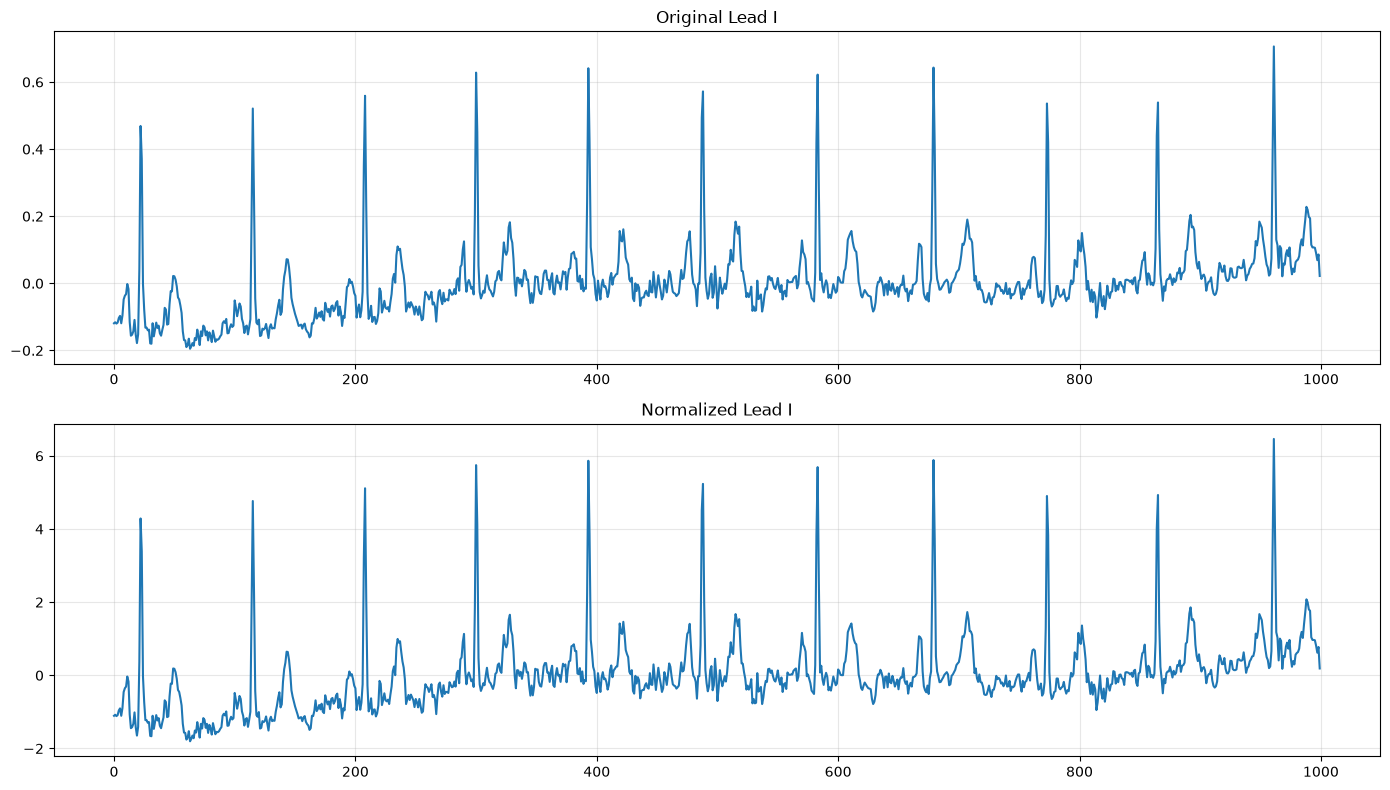

In [24]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8))

axes[0].plot(signal[:, 0])

axes[0].set_title("Original Lead I")

axes[0].grid(alpha=0.3)

axes[1].plot(normalized_signal[:, 0])

axes[1].set_title("Normalized Lead I")

axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [25]:
class PTBXLSignalDataset(Dataset):

    def __init__(
        self,
        dataframe,
        base_dir,
        label_columns,
    ):
        self.dataframe = dataframe.reset_index(drop=True)

        self.base_dir = Path(base_dir)

        self.label_columns = label_columns

    def __len__(self):

        return len(self.dataframe)

    def __getitem__(
        self,
        index,
    ):

        row = self.dataframe.iloc[index]

        record = wfdb.rdrecord(str(self.base_dir / row["filename_lr"]))

        signal = record.p_signal.astype(np.float32)

        signal = normalize_ecg(signal)

        # Convert from:
        # (samples, leads)
        # to:
        # (leads, samples)
        signal = signal.T

        labels = row[self.label_columns].to_numpy(dtype=np.float32)

        return (
            torch.tensor(signal, dtype=torch.float32),
            torch.tensor(labels, dtype=torch.float32),
        )

In [26]:
train_dataset = PTBXLSignalDataset(train_df, PTBXL_DIR, label_columns)

val_dataset = PTBXLSignalDataset(val_df, PTBXL_DIR, label_columns)

test_dataset = PTBXLSignalDataset(test_df, PTBXL_DIR, label_columns)

In [27]:
X, y = train_dataset[0]

print("Signal shape:", X.shape)

print("Label shape:", y.shape)

print("Labels:", y)

Signal shape: torch.Size([12, 1000])
Label shape: torch.Size([5])
Labels: tensor([1., 0., 0., 0., 0.])


In [28]:
print("Target classes:", TARGET_CLASSES)

print("First target:", y.numpy())

Target classes: ['NORM', 'MI', 'STTC', 'CD', 'HYP']
First target: [1. 0. 0. 0. 0.]


In [29]:
preprocessing_summary = {
    "sampling_frequency": 100,
    "num_leads": 12,
    "target_classes": TARGET_CLASSES,
    "task": "multi-label classification",
    "removed_unlabeled_records": int(len(df) - len(df_model)),
    "train_samples": int(len(train_df)),
    "validation_samples": int(len(val_df)),
    "test_samples": int(len(test_df)),
}

In [30]:
with open(REPORTS_DIR / "ptbxl_ecg_preprocessing_summary.json", "w") as f:
    json.dump(preprocessing_summary, f, indent=4)

In [31]:
train_df.to_csv(PROCESSED_DIR / "ptbxl_train.csv", index=False)

val_df.to_csv(PROCESSED_DIR / "ptbxl_val.csv", index=False)

test_df.to_csv(PROCESSED_DIR / "ptbxl_test.csv", index=False)